# Thống kê dữ liệu bình luận Mưa Đỏ


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Nếu mở notebook trong VS Code, thư mục làm việc có thể là notebooks hoặc BTL1-NLP.
duong_dan = Path.cwd().resolve()
while not (duong_dan / 'xu_ly_data').is_dir():
    if duong_dan == duong_dan.parent:
        raise FileNotFoundError('Hãy mở notebook trong thư mục dự án BTL1-NLP')
    duong_dan = duong_dan.parent
thu_muc = duong_dan / 'xu_ly_data'
anh = thu_muc / 'bieu_do_thong_ke'
anh.mkdir(parents=True, exist_ok=True)

## 1. Dữ liệu đầu vào sau khi crawl
Thống kê số link trong `post_urls.txt`.

In [2]:
with open(thu_muc / 'data/crawl_data/post_urls.txt', encoding='utf-8-sig') as f:
    links = [dong.strip() for dong in f if dong.strip() and not dong.lstrip().startswith('#')]
print('Tổng số dòng link:', len(links))
print('Số link khác nhau:', len(set(links)))
print('Số dòng link trùng:', len(links) - len(set(links)))

Tổng số dòng link: 98
Số link khác nhau: 98
Số dòng link trùng: 0


Trùng nội dung được tính sau khi chuẩn hóa Unicode, chữ thường và khoảng trắng, không tính dòng xuất hiện đầu tiên.

Tổng số mẫu crawl: 6539
Số dòng trùng nội dung: 449
Số dòng nội dung rỗng: 0


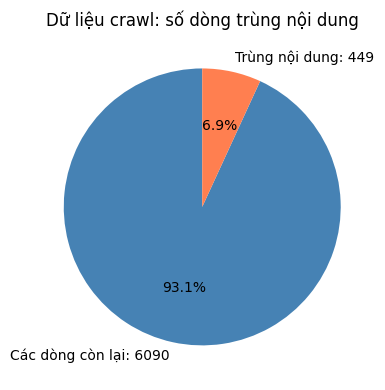

In [3]:
df_crawl = pd.read_csv(thu_muc / 'data/crawl_data/facebook_comments_all.csv', dtype=str).fillna('')
noi_dung = df_crawl['comment'].str.normalize('NFC').str.lower().str.replace(r'\s+', ' ', regex=True).str.strip()
trung = noi_dung[noi_dung != ''].duplicated().sum()
print('Tổng số mẫu crawl:', len(df_crawl))
print('Số dòng trùng nội dung:', trung)
print('Số dòng nội dung rỗng:', (noi_dung == '').sum())
plt.figure(figsize=(7, 4))
plt.pie([len(df_crawl) - trung, trung], labels=[f'Các dòng còn lại: {len(df_crawl) - trung}', f'Trùng nội dung: {trung}'], autopct='%1.1f%%', colors=['steelblue', 'coral'], startangle=90)
plt.title('Dữ liệu crawl: số dòng trùng nội dung')
plt.tight_layout()
plt.savefig(anh / '01_du_lieu_crawl_tron.png', dpi=180)
plt.show()

#### Kiểm tra trùng theo ID bình luận và bài viết

In [4]:
# Mỗi cặp comment_id + post_url được coi là một bình luận nguồn duy nhất.
# Dòng trùng là các lần xuất hiện dư sau lần đầu.
df_crawl['comment_id'] = df_crawl['comment_id'].astype(str).str.strip()
df_crawl['post_url'] = df_crawl['post_url'].astype(str).str.strip()
hop_le = df_crawl['comment_id'].ne('') & df_crawl['post_url'].ne('')
cap_id_bai = df_crawl.loc[hop_le, ['comment_id', 'post_url']]
dong_trung_id_bai = cap_id_bai.duplicated(keep='first')
nhom_trung_id_bai = cap_id_bai[dong_trung_id_bai | cap_id_bai.duplicated(keep=False)].drop_duplicates().shape[0]
print('Số dòng crawl có đủ comment_id và post_url:', len(cap_id_bai))
print('Số cặp comment_id + post_url bị lặp (dòng dư):', int(dong_trung_id_bai.sum()))
print('Số cặp ID bài viết bị trùng:', nhom_trung_id_bai)
print('Số dòng thiếu comment_id hoặc post_url:', int((~hop_le).sum()))

Số dòng crawl có đủ comment_id và post_url: 6539
Số cặp comment_id + post_url bị lặp (dòng dư): 0
Số cặp ID bài viết bị trùng: 0
Số dòng thiếu comment_id hoặc post_url: 0


## 2. Dữ liệu đã gán nhãn
Dữ liệu gốc và synthetic được lưu ở hai file riêng.


Tổng số mẫu: 6539
Số mẫu theo nhãn:
label
non-toxic    6489
toxic          50
Name: count, dtype: int64
Số biến thể AI: 0


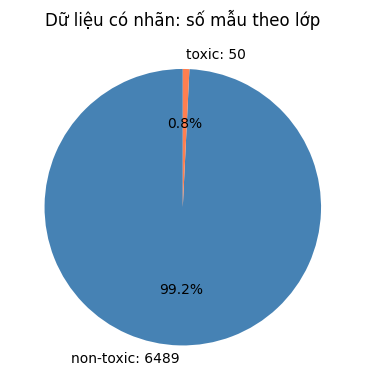

In [5]:
df = pd.read_csv(thu_muc / 'data/data/input/data_original.csv', dtype=str).fillna('')
df['label'] = df['label'].str.strip().str.lower().replace({'0': 'non-toxic', '1': 'toxic'})
print('Tổng số mẫu:', len(df))
print('Số mẫu theo nhãn:')
print(df['label'].value_counts())
print('Số biến thể AI:', df['is_synthetic'].str.lower().isin(['true', '1']).sum())
so_luong = df['label'].value_counts().reindex(['non-toxic', 'toxic'], fill_value=0)
plt.figure(figsize=(7, 4))
plt.pie(so_luong.values, labels=[f'{ten}: {so}' for ten, so in so_luong.items()], autopct='%1.1f%%', colors=['steelblue', 'coral'], startangle=90)
plt.title('Dữ liệu có nhãn: số mẫu theo lớp')
plt.tight_layout()
plt.savefig(anh / '02_nhan_dau_vao_tron.png', dpi=180)
plt.show()

### Số mẫu theo lớp của dữ liệu nguyên bản
Chỉ tính các dòng `is_synthetic = False`, không gồm biến thể AI.

Tổng mẫu nguyên bản: 6539
label
non-toxic    6489
toxic          50
Name: count, dtype: int64


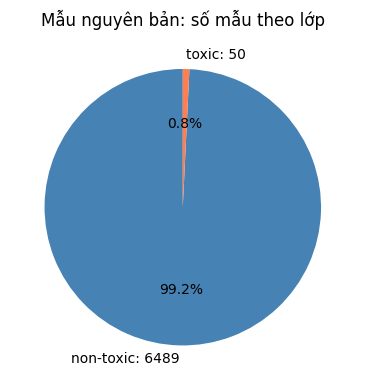

In [6]:
df_nguyen_ban = df[df['is_synthetic'].str.lower().isin(['false', '0'])]
so_luong_goc = df_nguyen_ban['label'].value_counts().reindex(['non-toxic', 'toxic'], fill_value=0)
print('Tổng mẫu nguyên bản:', len(df_nguyen_ban))
print(so_luong_goc)
plt.figure(figsize=(7, 4))
plt.pie(so_luong_goc.values, labels=[f'{ten}: {so}' for ten, so in so_luong_goc.items()], autopct='%1.1f%%', colors=['steelblue', 'coral'], startangle=90)
plt.title('Mẫu nguyên bản: số mẫu theo lớp')
plt.tight_layout()
plt.savefig(anh / '06_nhan_mau_nguyen_ban_tron.png', dpi=180)
plt.show()

In [7]:
df_synthetic = pd.read_csv(thu_muc / 'data/data/input/data_synthetic.csv', dtype=str).fillna('')
print('Số mẫu gốc đã gán nhãn:', len(df))
print('Số biến thể synthetic đã sinh trước đây:', len(df_synthetic))


Số mẫu gốc đã gán nhãn: 6539
Số biến thể synthetic đã sinh trước đây: 396


## 3. Dữ liệu gốc sau tiền xử lý, trước chia tập
Nguồn comments_preprocessed.csv chỉ gồm bình luận gốc.


Tổng số mẫu: 6031
Số mẫu theo nhãn:
label
non-toxic    5982
toxic          49
Name: count, dtype: int64
Số biến thể AI: 0
Số dòng giảm so với đầu vào có nhãn: 508


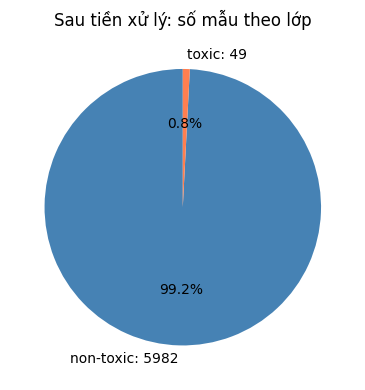

In [8]:
df_processed = pd.read_csv(thu_muc / 'data/data/pre_split/comments_preprocessed.csv', dtype=str).fillna('')
df_processed['label'] = df_processed['label'].str.strip().str.lower().replace({'0': 'non-toxic', '1': 'toxic'})
print('Tổng số mẫu:', len(df_processed))
print('Số mẫu theo nhãn:')
print(df_processed['label'].value_counts())
print('Số biến thể AI:', df_processed['is_synthetic'].str.lower().isin(['true', '1']).sum())
print('Số dòng giảm so với đầu vào có nhãn:', len(df) - len(df_processed))
so_luong_sau = df_processed['label'].value_counts().reindex(['non-toxic', 'toxic'], fill_value=0)
plt.figure(figsize=(7, 4))
plt.pie(so_luong_sau.values, labels=[f'{ten}: {so}' for ten, so in so_luong_sau.items()], autopct='%1.1f%%', colors=['steelblue', 'coral'], startangle=90)
plt.title('Sau tiền xử lý: số mẫu theo lớp')
plt.tight_layout()
plt.savefig(anh / '04_nhan_sau_xu_ly_tron.png', dpi=180)
plt.show()

Số dòng trùng ở mục 1 có thể khác số dòng bị loại trong tiền xử lý vì hai bước dùng cách so sánh văn bản khác nhau.

## Phân bố nhãn trong các tập theo post

Train gồm dữ liệu gốc và synthetic được ghép sau khi chia; test và validation chỉ chứa dữ liệu gốc.

           Train  Test  Validation
Non-toxic   4184  1192         606
Toxic        428     9           6


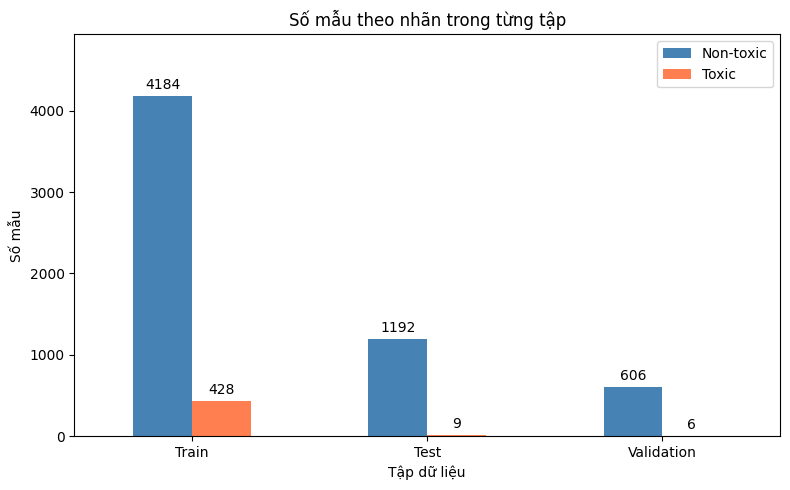

In [9]:
thu_muc_chia = thu_muc / 'data/data/split_all_comments/data_split_by_post'
df_train = pd.read_csv(thu_muc_chia / 'train.csv', dtype=str).fillna('')
df_test = pd.read_csv(thu_muc_chia / 'test.csv', dtype=str).fillna('')
df_validation = pd.read_csv(thu_muc_chia / 'validation.csv', dtype=str).fillna('')

bang = pd.DataFrame({
    'Train': df_train['label'].value_counts(),
    'Test': df_test['label'].value_counts(),
    'Validation': df_validation['label'].value_counts()
}).fillna(0).astype(int).reindex(['0', '1'])
bang.index = ['Non-toxic', 'Toxic']
print(bang)

ax = bang.T.plot(kind='bar', figsize=(8, 5), color=['steelblue', 'coral'])
for cot in ax.containers:
    ax.bar_label(cot, padding=3)
ax.set_title('Số mẫu theo nhãn trong từng tập')
ax.set_xlabel('Tập dữ liệu')
ax.set_ylabel('Số mẫu')
ax.set_ylim(0, bang.to_numpy().max() * 1.18)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(anh / '08_nhan_theo_tap.png', dpi=180)
plt.show()

## 4. Tập train trước và sau oversampling

Oversampling được thực hiện sau khi ghép synthetic vào train.

Trước oversampling: 4612 mẫu; non-toxic: 4184 ; toxic: 428
Sau oversampling: 8368 mẫu; non-toxic: 4184 ; toxic: 4184
Số dòng được lấy lặp thêm: 3756


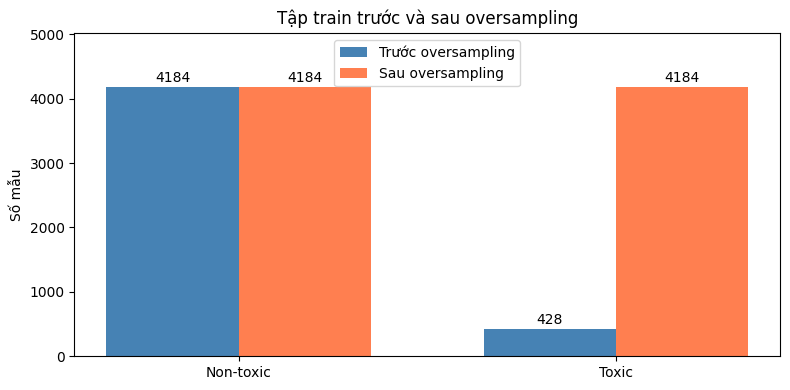

In [10]:
duong_dan_oversampling = thu_muc / 'data/data/split_all_comments/data_oversampling/train_oversampled.csv'
if not duong_dan_oversampling.exists():
    print('Chưa oversampling: hãy sinh synthetic từ train, ghép dữ liệu mới rồi chạy oversampling.')
else:
    df_train = pd.read_csv(thu_muc / 'data/data/split_all_comments/data_split_by_post/train.csv', dtype=str).fillna('')
    df_oversampling = pd.read_csv(thu_muc / 'data/data/split_all_comments/data_oversampling/train_oversampled.csv', dtype=str).fillna('')

    truoc = df_train['label'].value_counts().reindex(['0', '1'], fill_value=0)
    sau = df_oversampling['label'].value_counts().reindex(['0', '1'], fill_value=0)
    print('Trước oversampling:', len(df_train), 'mẫu; non-toxic:', truoc['0'], '; toxic:', truoc['1'])
    print('Sau oversampling:', len(df_oversampling), 'mẫu; non-toxic:', sau['0'], '; toxic:', sau['1'])
    print('Số dòng được lấy lặp thêm:', len(df_oversampling) - len(df_train))

    plt.figure(figsize=(8, 4))
    plt.bar([0, 1], truoc.values, width=0.35, label='Trước oversampling', color='steelblue')
    plt.bar([0.35, 1.35], sau.values, width=0.35, label='Sau oversampling', color='coral')
    for x, gia_tri in zip([0, 1], truoc.values):
        plt.text(x, gia_tri + 80, str(gia_tri), ha='center')
    for x, gia_tri in zip([0.35, 1.35], sau.values):
        plt.text(x, gia_tri + 80, str(gia_tri), ha='center')
    plt.xticks([0.175, 1.175], ['Non-toxic', 'Toxic'])
    plt.ylim(0, max(sau.max(), truoc.max()) * 1.2)
    plt.ylabel('Số mẫu')
    plt.title('Tập train trước và sau oversampling')
    plt.legend()
    plt.tight_layout()
    plt.savefig(anh / '07_train_oversampling.png', dpi=180)
    plt.show()

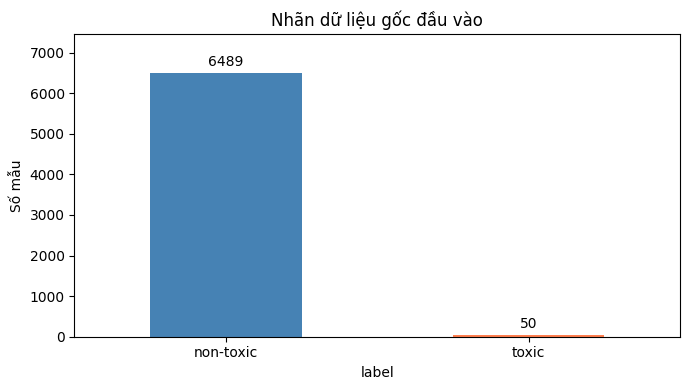

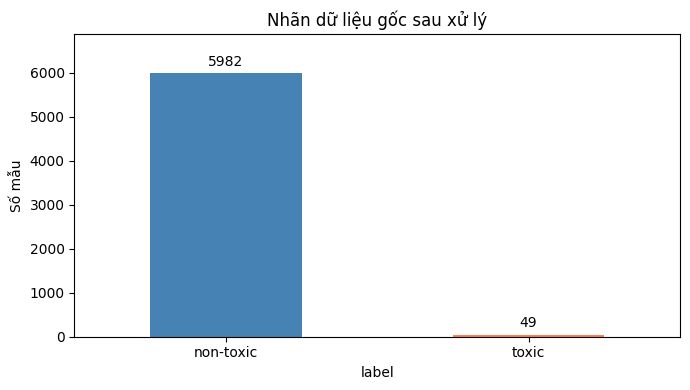

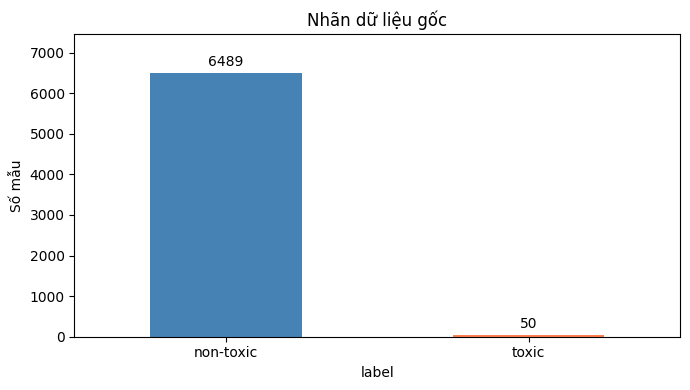

In [11]:
# Biểu đồ cột tương ứng các thống kê nhãn.
for du_lieu, ten, tieu_de in [(so_luong, '02_nhan_dau_vao.png', 'Nhãn dữ liệu gốc đầu vào'), (so_luong_sau, '04_nhan_sau_xu_ly.png', 'Nhãn dữ liệu gốc sau xử lý'), (so_luong_goc, '06_nhan_mau_nguyen_ban.png', 'Nhãn dữ liệu gốc')]:
    ax = du_lieu.plot.bar(figsize=(7, 4), color=['steelblue', 'coral'])
    for cot in ax.containers:
        ax.bar_label(cot, padding=3)
    ax.set_title(tieu_de)
    ax.set_ylabel('Số mẫu')
    ax.set_ylim(0, max(du_lieu.max() * 1.15, 1))
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(anh / ten, dpi=180)
    plt.show()